# Validating CoLoRe simulation for CMB lensing

- The CoLoRe simulation boxes were first generated by Laura Casas
- The notebook just uses the CMB lensing convergence $\kappa$ values of the boxes and validates it through the auto-spectrum.
- These convergence values can be found in `data/first_test_box/`. 
    - `out_kappa_zstar3.8.fits` is set with the source plane to be at the max redshift of the box, i.e. $z_* = z_{\rm max} = 3.8$
    - `out_kappa_zstar1100.fits` is set with the standard last scattering surface $z_* = 1100$.
- The notebook also compares the results between the two datasets from CoLoRe to asses the difference in the last scattering surface.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import camb
import healpy as hp
from scipy.integrate import quad
from scipy.constants import c

In [3]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": 'serif',
})

# Theory CMB lensing auto-spectrum $C_{\ell}^{\kappa \kappa}$

## setting up CAMB

In [4]:
# set either linear or nonlinear PK and cosmological parameters matching CoLoRe simulation
H0 = 67.31
h0 = H0 / 100
ombh2 = 0.04904 * h0**2
omch2 = (0.3147 * h0**2) - ombh2
s8 = 0.83

In [5]:
# set the k and redshift range for the boltzmann solver
kmin, kmax = 1E-3, 100
zmin, zmax = 0, 1100
nz = 200
zs = zmin + np.exp(np.log(zmax - zmin + 1)*np.linspace(0, 1, nz)) - 1

# range of multipoles of the power spectrum to be studied
lmin = 2
lmax = 2500
ells = np.arange(lmin, lmax+1)

In [6]:
def get_camb_results(zs, kmax, lmax, NonLinear, lens_potential_accuracy):
    '''
    Get results.CAMBdata instance from a cosmology
    '''
    
    # matching CoLoRe cosmology parameters

    # set up nonlinearity
    pars = camb.set_params(NonLinear=NonLinear,
                           halofit_version='mead2020') # For non-linear corrections
    
    # set up cosmological parameters
    pars.set_cosmology(
        H0=H0, 
        ombh2=ombh2, 
        omch2=omch2, 
        mnu=0.06, 
        omk=0, 
        tau=0.0544)
    
    # set up primordial power spectrum amplitude and spectral index
    pars.InitPower.set_params(ns=0.9655)
    
    # set up matter power spectrum parameters
    pars.set_matter_power(redshifts=zs, kmax=kmax)
    pars.set_dark_energy(w=-1.0)

    # set lens potential accuracy to get CAMB's internal calculation accurate at the 1% level at L~2000
    # Increase to 4 for accurate match to the Limber calculation here
    pars.set_for_lmax(lmax=lmax, 
                      lens_potential_accuracy=lens_potential_accuracy)
    
    # generate a CAMBdata instance with the set cosmology
    results = camb.get_results(pars)

    
    # adjust primordial power spectrum amplitude for sigma8 to match
    As_new = pars.InitPower.As * (s8**2 / results.get_sigma8_0()**2)
    pars.InitPower.set_params(As=As_new)
    results = camb.get_results(pars)

    # adjusting have to be done twice to account for deviations in the A propto sigma**2 relation (due to neutrino mass etc)
    As_new = pars.InitPower.As * (s8**2 / results.get_sigma8_0()**2)
    pars.InitPower.set_params(As=As_new)
    results = camb.get_results(pars)

    return results

In [7]:
# get linear and non-linear matter power spectrum
results_lin = get_camb_results(zs, kmax, lmax, NonLinear='NonLinear_none', lens_potential_accuracy=0)
results_nonlin = get_camb_results(zs, kmax, lmax, NonLinear='NonLinear_both', lens_potential_accuracy=2)

Note: redshifts have been re-sorted (earliest first)
Note: redshifts have been re-sorted (earliest first)


In [21]:
# redshift and comoving distance of the last scattering surface
# both lin and nonlin produce the same z_star
z_s = results_nonlin.get_derived_params().get('zstar')
z_max = 3.8  # max redshift of the CoLoRe simulation
chi_star = results_nonlin.comoving_radial_distance(z_s)
chi_max = results_nonlin.comoving_radial_distance(z_max)  # comoving distance of z_max

## manual Limber integral

In [22]:
def w_kappa(chi, z_chi, chi_s):
    '''
    CMB lensing convergence kernel
    '''
    
    a = 1.0 / (1.0 + z_chi)
    c_kms = c*1E-3
    
    
    w_prefactor = (1.5) * (H0/c_kms)**2 * om * (chi_s - chi)/chi_s
    w_geom = (chi/a)
    
    return w_prefactor * w_geom

In [23]:
def limber(chi, ell, chi_s, pk_interp, results):
    '''
    CMB lensing auto-spectrum using Limber approximation
    '''

    # converting chi to redshift
    z_chi = results.redshift_at_comoving_radial_distance(chi)
    k = (ell + 0.5) / chi
    

    # kernel and pk interpolator, filtering out of extrapolation k and small k
    if 1e-4 < k < kmax:
        win = w_kappa(chi, z_chi, chi_s)
        pk = pk_interp.P(z_chi, k, grid=False)
        return (win**2 / chi**2) * pk
        
    else:
        return 0

In [24]:
# get the linear and non-linear matter power spectrum interpolators
# disabling k units and hubble units and using the delta matter fields
pk_interp_lin = results_lin.get_matter_power_interpolator(nonlinear=False, 
                                                      hubble_units=False, 
                                                      k_hunit=False,  
                                                      var1='delta_tot', 
                                                      var2='delta_tot')
pk_interp_nonlin = results_nonlin.get_matter_power_interpolator(nonlinear=True, 
                                                                hubble_units=False, 
                                                                k_hunit=False,  
                                                                var1='delta_tot', 
                                                                var2='delta_tot')
om = results_nonlin.get_Omega('cdm', 0) + results_nonlin.get_Omega('baryon', 0)

In [25]:
#store the cls from linear and nonlinear limber approximation integration
# redshift integration up to zstar
cl_kk_lin_zs_zs = np.zeros(ells.shape)
cl_kk_nlin_zs_zs = np.zeros(ells.shape)

# redshift integration up to zmax
cl_kk_lin_zmax_zs = np.zeros(ells.shape)
cl_kk_nlin_zmax_zs = np.zeros(ells.shape)
cl_kk_lin_zmax_zmax = np.zeros(ells.shape)
cl_kk_nlin_zmax_zmax = np.zeros(ells.shape)

# manually integrate the limber approximation
for i, ell in enumerate(ells):
    
    # integral up to redshift z_star, source plane at z_star
    cl_kk_lin_zs_zs[i] = quad(limber, 0.001, chi_star, args=(ell, chi_star, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zs_zs[i] = quad(limber, 0.001, chi_star, args=(ell, chi_star, pk_interp_nonlin, results_nonlin), epsabs=1E-10)[0]
    
    # integral up to redshift z_max, source plane at z_star
    cl_kk_lin_zmax_zs[i] = quad(limber, 0.001, chi_max, args=(ell, chi_star, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zmax_zs[i] = quad(limber, 0.001, chi_max, args=(ell, chi_star, pk_interp_nonlin, results_nonlin), epsabs=1E-10)[0]

    # integral up to redshift z_max, source plane at z_max
    cl_kk_lin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_max, pk_interp_lin, results_lin), epsabs=1E-10)[0]
    cl_kk_nlin_zmax_zmax[i] = quad(limber, 0.001, chi_max, args=(ell, chi_max, pk_interp_nonlin, results_nonlin), epsabs=1E-10)[0]

## full sky (non-Limber) integral

In [26]:
# compute the lens potential cls from camb using full curved sky without Limber approx
cl_kk_camb_lin = results_lin.get_lens_potential_cls(lmax=lmax, raw_cl=True)[2:, 0]
cl_kk_camb_lin *= ((ells * (ells + 1.0)) / 2) ** 2  # converting cls_potential to cls_kappa
cl_kk_camb_nlin = results_nonlin.get_lens_potential_cls(lmax=lmax, raw_cl=True)[2:, 0]
cl_kk_camb_nlin *= ((ells * (ells + 1.0)) / 2) ** 2 # converting cls_potential to cls_kappa

# CoLoRe simulation auto-spectrum $C_{\ell}^{\kappa \kappa}$

In [55]:
first_test_box_cls_log = np.load(f'../data/first_test_box/cl_kk_log.npz')
second_test_box_cls_log = np.load(f'../data/second_test_box/cl_kk_log.npz')
ells_colore, cl_kk_colore_zmax, err_tt_zmax = first_test_box_cls_log['ells'], first_test_box_cls_log['cls'], first_test_box_cls_log['err']
ells_colore, cl_kk_colore_zs, err_tt_zs = second_test_box_cls_log['ells'], second_test_box_cls_log['cls'], second_test_box_cls_log['err']

# plotting

## compare Limber vs non-Limber with the second CoLoRe box

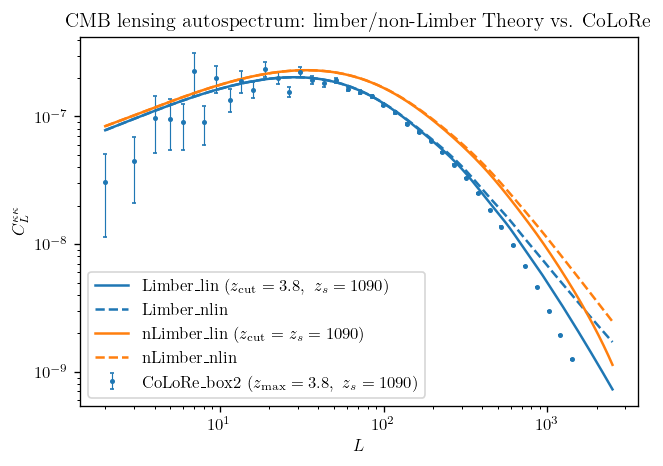

In [116]:
plt.figure(figsize=(6, 4), dpi=120)

# plot the rebinned Cls with error bars
plt.errorbar(ells_colore, cl_kk_colore_zs, yerr=err_tt_zs, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=4.0, label=r'CoLoRe_box2 ($z_{\rm max} = 3.8, \ z_s=1090$)')
# plt.errorbar(ells_colore, cl_kk_colore_zmax, yerr=err_tt_zmax, elinewidth=0.7, capsize=1.0, fmt='C1.', markersize=4.0, label=r'CoLoRe_box1 ($z_{\rm max} = z_s = 3.8$)')

# manual limber integration full redshift
plt.loglog(ells, cl_kk_lin_zmax_zs, c='C0', ls='-', label=r'Limber_lin ($z_{\rm cut} = 3.8, \ z_s=1090$)')
plt.loglog(ells, cl_kk_nlin_zmax_zs, c='C0', ls='--', label='Limber_nlin')


# full sky integration full redshift
plt.loglog(ells, cl_kk_camb_lin, c='C1', ls='-', label=r'nLimber_lin ($z_{\rm cut} = z_s=1090$)')
plt.loglog(ells, cl_kk_camb_nlin, c='C1', ls='--', label='nLimber_nlin')


plt.xlabel(r'$L$')
plt.ylabel(r'$C_{L}^{\kappa \kappa}$')


plt.title('CMB lensing autospectrum: limber/non-Limber Theory vs. CoLoRe')
plt.legend()

plt.savefig(f'plots/cls_kk_limber_comparison.png', bbox_inches='tight')
plt.savefig(f'plots/cls_kk_limber_comparison.pdf', bbox_inches='tight')
plt.show()

## comparing CoLoRe boxes
source plane changes between them

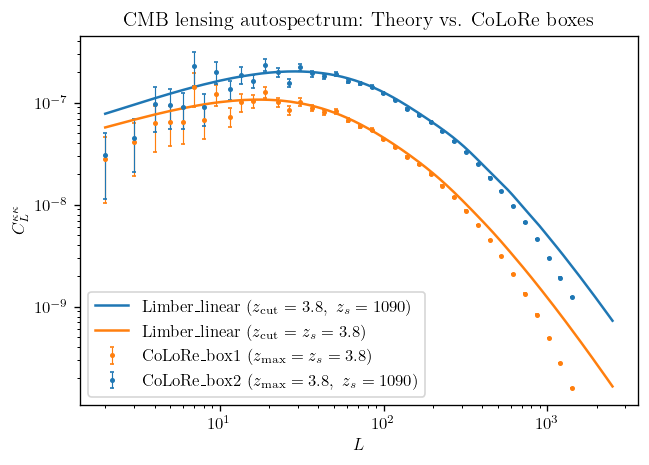

In [112]:
plt.figure(figsize=(6, 4), dpi=120)

# plot the rebinned Cls with error bars
plt.errorbar(ells_colore, cl_kk_colore_zmax, yerr=err_tt_zmax, elinewidth=0.7, capsize=1.0, fmt='C1.', markersize=4.0, label=r'CoLoRe_box1 ($z_{\rm max} = z_s = 3.8$)')
plt.errorbar(ells_colore, cl_kk_colore_zs, yerr=err_tt_zs, elinewidth=0.7, capsize=1.0, fmt='C0.', markersize=4.0, label=r'CoLoRe_box2 ($z_{\rm max} = 3.8, \ z_s=1090$)')

# manual limber integration full redshift
plt.plot(ells, cl_kk_lin_zmax_zs, c='C0', ls='-', label=r'Limber_linear ($z_{\rm cut} = 3.8, \ z_s=1090$)')
plt.plot(ells, cl_kk_lin_zmax_zmax, c='C1', ls='-', label=r'Limber_linear ($z_{\rm cut} = z_s = 3.8$)')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$L$')
plt.ylabel(r'$C_{L}^{\kappa \kappa}$')

plt.title('CMB lensing autospectrum: Theory vs. CoLoRe boxes')
plt.legend()

plt.savefig(f'plots/cls_kk_boxes_comparison.png', bbox_inches='tight')
plt.savefig(f'plots/cls_kk_boxes_comparison.pdf', bbox_inches='tight')
plt.show()

## comparing Limber approximation: linear vs. nonlinear

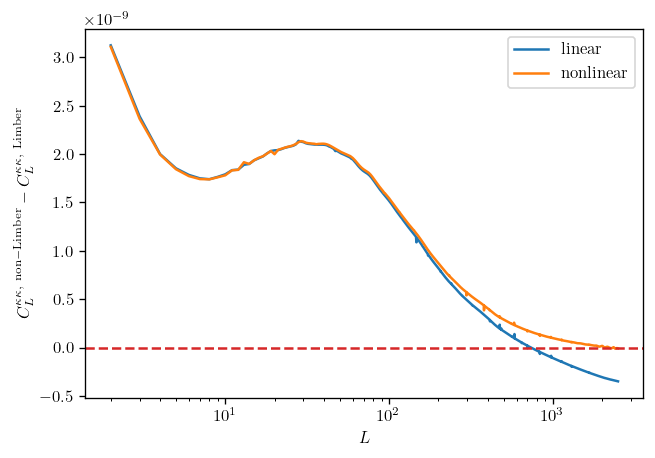

In [113]:
plt.figure(figsize=(6, 4), dpi=120)

# compare linear and nonlinear
plt.semilogx(ells, cl_kk_camb_lin - cl_kk_lin_zs_zs, label='linear')
plt.semilogx(ells, cl_kk_camb_nlin - cl_kk_nlin_zs_zs, label='nonlinear')
plt.axhline(0, c='C3', ls='--')

plt.xlabel(r'$L$')
plt.ylabel(r'$C_{L}^{\kappa \kappa, \ \rm non-Limber} - C_{L}^{\kappa \kappa, \ \rm Limber}$')

plt.legend()

plt.savefig(f'plots/cls_kk_full-vs-limber.png', bbox_inches='tight')
plt.savefig(f'plots/cls_kk_full-vs-limber.pdf', bbox_inches='tight')
plt.show()